# Telco Customer Churn: who's leaving, why, and what it costs
**Ivan Ignacio Velazquez**, Data Analyst

_Originally my capstone project at Toronto School of Management (2024). Revised in November 2026 with corrected modeling, proper evaluation metrics and a business-impact layer._

**Business question:** a telecom provider loses about one in four customers. Which customers are most likely to leave, what drives it, and how much revenue could a retention program protect?

**Dataset:** IBM Telco Customer Churn sample (7,043 customers, 21 attributes: demographics, services, contract, billing and a churn flag).

**How to read this notebook:** it tells the story step by step. The reusable logic lives in the `churn/` package, so the notebook, `run_analysis.py` and the tests all use the same code and produce the same numbers.

### Key results
| Topic | Result |
|---|---|
| **Churn rate** | 26.5% of customers, taking **30.5% of monthly revenue** ($139k of $456k) with them |
| **Biggest driver** | Contract type: **42.7%** churn on month-to-month vs. **2.8%** on two-year contracts |
| **Riskiest moment** | The first year: **47.4%** churn in months 0–12 vs. 14.0% after month 24 |
| **Model** | Logistic regression: **ROC-AUC 0.84**, catches **80% of churners** (recall) vs. 0% for the "everyone stays" baseline |
| **Targeting** | The top risk band is **33% of customers but holds 71% of all churners** |
| **Impact (scenario)** | Retaining 20% of high-risk churners protects **~$20.8k/month (~$250k/year)** of revenue |

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

from churn import analysis, config, data, impact, model

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
OUT = config.OUTPUT_DIR
OUT.mkdir(exist_ok=True)

## 1. Load and clean the data

In [2]:
raw = data.load_raw()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


`TotalCharges` comes in as text. Before deciding how to handle its blanks, I checked who those customers are:

In [3]:
total = pd.to_numeric(raw["TotalCharges"].astype(str).str.strip(), errors="coerce")
print(f"Blank TotalCharges: {total.isna().sum()} rows")
print(f"Tenure of those customers: {sorted(raw.loc[total.isna(), 'tenure'].unique())}")

Blank TotalCharges: 11 rows
Tenure of those customers: [np.int64(0)]


All 11 blanks belong to customers with **0 months of tenure**: they signed up but hadn't been billed yet. So the right value is **0**, not a missing value to impute. `data.clean()` does that (and fails loudly if a blank ever shows up for a customer with tenure), turns `Churn` into 0/1 and drops the ID column.

In [4]:
df = data.clean(raw)
df.describe()

,tenure,MonthlyCharges,TotalCharges,Churn
count,"7,043.000","7,043.000","7,043.000","7,043.000"
mean,32.371,64.762,"2,279.734",0.265
std,24.559,30.090,"2,266.794",0.442
min,0.000,18.250,0.000,0.000
25%,9.000,35.500,398.550,0.000
50%,29.000,70.350,"1,394.550",0.000
75%,55.000,89.850,"3,786.600",1.000
max,72.000,118.750,"8,684.800",1.000


## 2. The business problem in numbers

In [5]:
f = analysis.headline_figures(df)
print(f"Customers:  {f['customers']:,}")
print(f"Churn rate: {f['churn_rate']:.1%}")
print(f"Monthly revenue that left with churned customers: "
      f"${f['lost_monthly_revenue']:,.0f} of ${f['monthly_revenue']:,.0f} "
      f"({f['lost_monthly_revenue'] / f['monthly_revenue']:.1%})")

Customers:  7,043
Churn rate: 26.5%
Monthly revenue that left with churned customers: $139,131 of $456,117 (30.5%)


## 3. Who churns?
The dashed line in each chart is the overall churn rate. Orange bars are segments above it.

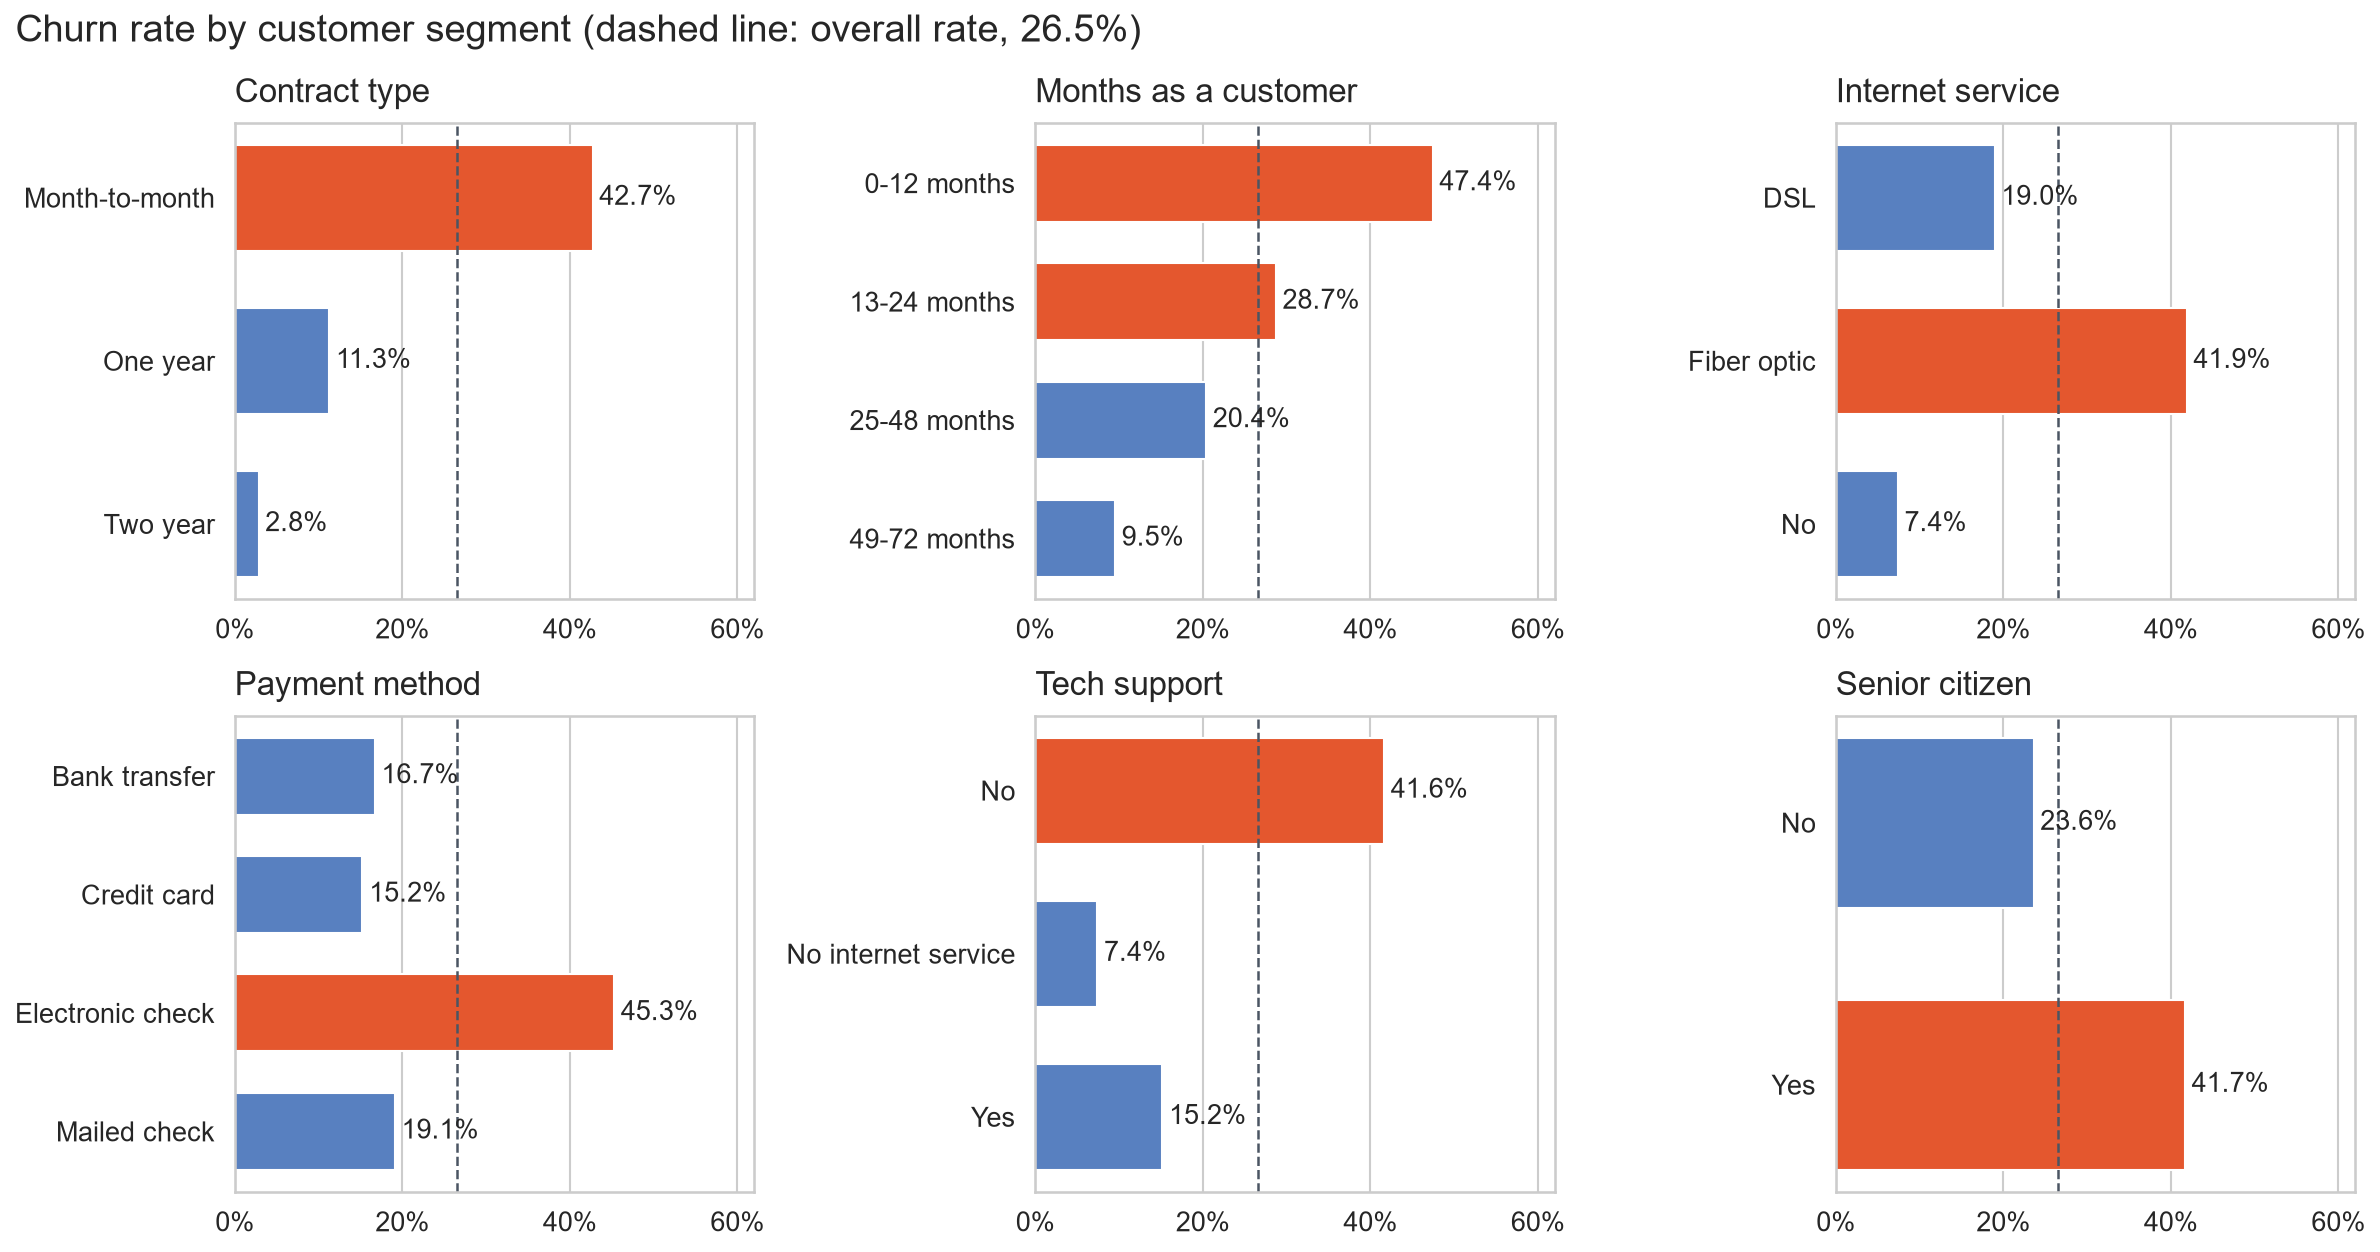

In [6]:
analysis.plot_segments(data.add_tenure_group(df), OUT / "churn_by_segment.png")
display(Image(filename=OUT / "churn_by_segment.png"))

In [7]:
# The figures quoted in the README and the presentation, all from one function
(pd.Series({k: v for k, v in f.items() if k.startswith(("churn_", "month_"))})
   .map("{:.1%}".format).rename("value").to_frame())

,value
churn_rate,26.5%
churn_month_to_month,42.7%
churn_one_year,11.3%
churn_two_year,2.8%
churn_first_12_months,47.4%
churn_after_24_months,14.0%
churn_fiber,41.9%
churn_electronic_check,45.3%
churn_no_tech_support,41.6%
churn_seniors,41.7%


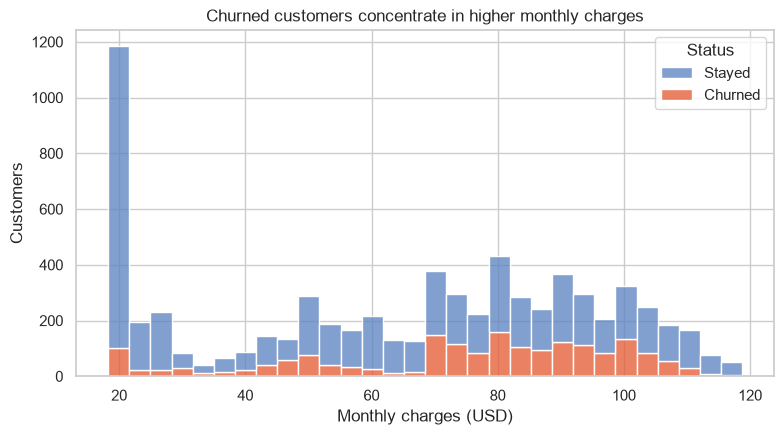

Churn
stayed    61.270
churned   74.440
Name: MonthlyCharges, dtype: float64


In [8]:
# Exploration only (not part of the pipeline): do churners pay more?
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df.assign(Status=df["Churn"].map({0: "Stayed", 1: "Churned"})),
             x="MonthlyCharges", hue="Status", hue_order=["Stayed", "Churned"],
             bins=30, multiple="stack", palette=[config.BLUE, config.ORANGE], ax=ax)
ax.set(xlabel="Monthly charges (USD)", ylabel="Customers",
       title="Churned customers concentrate in higher monthly charges")
plt.show()
print(df.groupby("Churn")["MonthlyCharges"].mean().rename({0: "stayed", 1: "churned"}).round(2))

## 4. Which differences are statistically real?
A **chi-square test of independence** for each categorical variable against churn. A p-value above 0.05 means we can't claim the variable is related to churn.

In [9]:
analysis.chi_square_tests(df)

,variable,chi2,p_value,related_to_churn
0,Contract,"1,184.597",0.000,True
1,OnlineSecurity,849.999,0.000,True
2,TechSupport,828.197,0.000,True
3,InternetService,732.310,0.000,True
4,PaymentMethod,648.142,0.000,True
5,OnlineBackup,601.813,0.000,True
6,DeviceProtection,558.419,0.000,True
7,StreamingMovies,375.661,0.000,True
8,StreamingTV,374.204,0.000,True
9,PaperlessBilling,258.278,0.000,True


**Gender and phone service show no relationship with churn.** This corrects the original capstone, which read an OLS on gender (p = 0.47) as a predictive equation. Knowing what does **not** matter is as useful to the business as knowing what does.

## 5. Predictive model
**Design choices:**
- **Stratified 70/30 split**, so train and test keep the 26.5% churn share.
- **Everything inside a scikit-learn `Pipeline`:** the scaler and the encoder are fitted on training data only, so no information leaks from the test set (`tests/test_churn.py` checks this).
- **A baseline that always predicts "stays".** Accuracy alone is misleading here: the baseline already scores ~73%.
- **Recall and ROC-AUC as main metrics:** missing a customer who leaves costs more than a retention offer to one who would have stayed.

In [10]:
features, target = model.features_and_target(df)
split = model.split(features, target)
pipes = model.build_pipelines(features)
print(f"Train: {len(split.X_train):,}  Test: {len(split.X_test):,}  "
      f"Churn share in test: {split.y_test.mean():.1%}")

results = model.evaluate(pipes, split)   # 5-fold CV on train, then fit and score on test
results.to_csv(OUT / "model_results.csv")
results

Train: 4,930  Test: 2,113  Churn share in test: 26.5%


,"CV ROC-AUC (train, 5-fold)",accuracy,precision,recall,F1,ROC-AUC
model,,,,,,
Baseline (always 'stays'),0.500,0.735,0.000,0.000,0.000,0.500
Logistic regression,0.844,0.744,0.512,0.797,0.623,0.844
Random forest,0.845,0.762,0.536,0.779,0.635,0.840


Selected model: Logistic regression


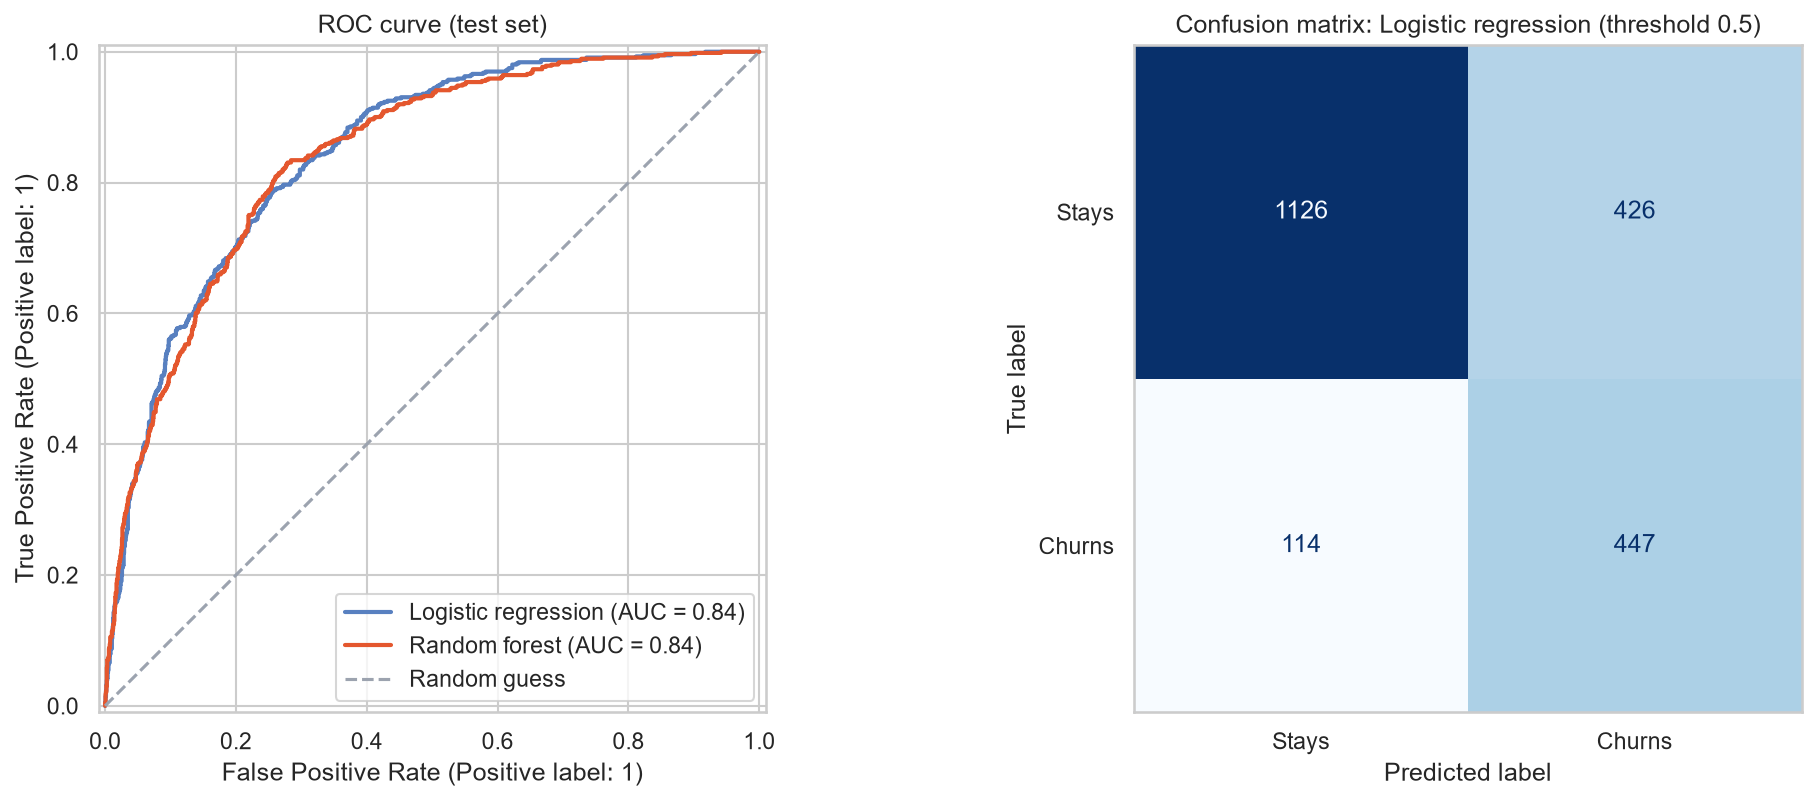

In [11]:
best_name = model.select_model(results)
best = pipes[best_name]
print(f"Selected model: {best_name}")

model.plot_evaluation(pipes, best_name, split, OUT / "model_evaluation.png")
display(Image(filename=OUT / "model_evaluation.png"))

Logistic regression and random forest perform the same (cross-validated ROC-AUC 0.844 vs. 0.845). The selection rule keeps the logistic regression on a tie (less than 0.005 apart): it's simpler and every prediction can be explained.

### Choosing the decision threshold
A lower threshold flags more customers: it catches more real churners (recall) but sends more offers to customers who would have stayed (lower precision). The right point depends on what the offer costs.

In [12]:
model.threshold_table(best, split)

,customers_flagged,recall,precision
threshold,,,
0.300,1216,0.929,0.428
0.400,1039,0.863,0.466
0.500,873,0.797,0.512
0.600,736,0.718,0.548
0.700,556,0.608,0.613


## 6. What drives churn?
**Odds ratios from the logistic regression.** 2.0 means the feature doubles the odds of churning; 0.5 halves them. Tenure is standardized, so its odds ratio is per one standard deviation (about two years). Monthly and total charges are left out of the chart because they overlap with tenure and their signs can't be read on their own; the permutation importance below doesn't have that problem.

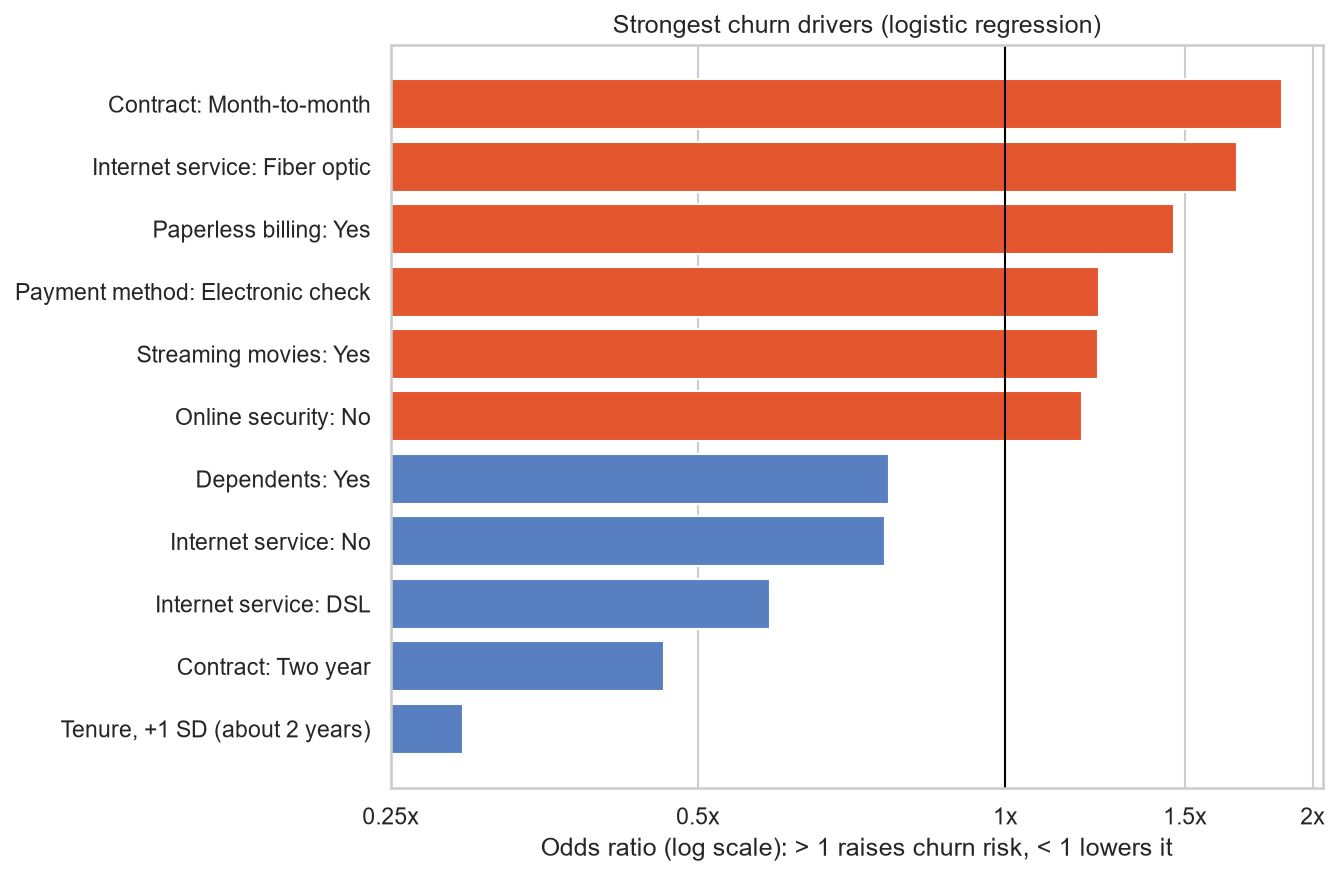

In [13]:
model.plot_drivers(model.odds_ratios(pipes[model.LOGIT]), OUT / "churn_drivers.png")
display(Image(filename=OUT / "churn_drivers.png"))

In [14]:
# How much test ROC-AUC drops when each column is shuffled
model.importance(best, split)

,feature,auc_drop
0,tenure,0.173
1,Contract,0.037
2,InternetService,0.036
3,MonthlyCharges,0.024
4,TotalCharges,0.018
5,PaymentMethod,0.004
6,StreamingMovies,0.003
7,OnlineSecurity,0.003
8,StreamingTV,0.003
9,TechSupport,0.003


## 7. Business impact
To score **every** customer without grading the model on data it was trained on, I use **out-of-fold predictions**: each customer's risk comes from a model that never saw that customer.

In [15]:
scored = impact.score_customers(best, raw, df, features, target, model.cv_splitter())
scored.to_csv(OUT / "customer_risk_scores.csv", index=False)   # input for the Power BI dashboard
impact.risk_bands(scored)

,customers,actual_churn_rate,churners,monthly_revenue,share_of_all_churners
risk_band,,,,,
Low,2970,0.048,144,"164,654.700",0.077
Medium,1715,0.233,400,"108,330.800",0.214
High,2358,0.562,1325,"183,131.100",0.709


In [16]:
# The save rate is an ASSUMPTION, not a result: change it here or with
# `python run_analysis.py --save-rate 0.3` to test other cases.
sc = impact.retention_scenario(scored, save_rate=config.SAVE_RATE, band=config.TARGET_BAND)
print(f"Customers to contact ({config.TARGET_BAND} risk): {sc['customers_contacted']:,} "
      f"({sc['share_of_base']:.0%} of the base)")
print(f"Real churners among them: {sc['churners_reached']:,} ({sc['share_of_churners']:.0%} of all churners)")
print(f"If the offer keeps {config.SAVE_RATE:.0%} of them: ${sc['saved_monthly']:,.0f}/month "
      f"(~${sc['saved_yearly']:,.0f}/year) of revenue protected, before the cost of the offer")

Customers to contact (High risk): 2,358 (33% of the base)
Real churners among them: 1,325 (71% of all churners)
If the offer keeps 20% of them: $20,813/month (~$249,762/year) of revenue protected, before the cost of the offer


## 8. Conclusions and recommendations
**What drives churn**
1. **Contract flexibility.** Month-to-month customers churn at 42.7% and make up 88.6% of all churners; two-year contracts churn at 2.8%.
2. **The first year.** Churn is 47.4% in the first 12 months and falls steadily with tenure (9.5% after four years).
3. **Fiber optic without support.** Fiber customers churn at 41.9%, and customers without tech support or online security churn at roughly 42%, almost three times the rate of those who have them.
4. **Payment by electronic check** (45.3% churn vs. 15–19% for the other methods).
5. **Gender and phone service don't matter** (chi-square p = 0.49 and 0.34).

**Model.** At a 0.5 threshold the logistic regression catches 80% of churners with 51% precision; lowering the threshold to 0.4 catches 86%.

**Recommendations**
1. **Contract migration offer:** a discount or perk for month-to-month customers in the high-risk band who switch to a one-year contract.
2. **First-90-days onboarding** for new customers: check-in calls, setup help, early satisfaction survey.
3. **Bundle tech support and online security** with fiber plans, the segment with the highest churn and highest bills.
4. **Incentivize automatic payment** (card or bank transfer) for electronic-check customers.
5. **Operationalize the score:** load `customer_risk_scores.csv` into the CRM, refresh it monthly and trigger retention tasks automatically for the high-risk band.

**Limitations:** a single snapshot (no time dimension), a public sample dataset, and observational data: these are associations, not proven causes. The retention scenario depends on the assumed save rate and doesn't subtract the cost of the offer.

## 9. What changed from the original capstone (v1)
| Issue in v1 | Fix in v2 |
|---|---|
| The label-encoding model re-mapped an already numeric `Churn` column, turning it into all zeros, and reported the accuracy of a different model | Removed; one clean pipeline with one-hot encoding |
| The scaler was re-fitted on the test set (`fit_transform`), leaking test information | Scaling and encoding fitted only on training data inside a `Pipeline`, checked by a test |
| Only accuracy reported (80%), with no baseline | Baseline (73.5%), precision, recall, F1, ROC-AUC, confusion matrix, cross-validation |
| OLS on gender read as a predictive equation | Chi-square tests: gender is **not** related to churn |
| Linear regression on a binary target, R² reported as "accuracy" | Logistic regression and random forest for churn |
| Some figures inconsistent between notebook and slides (e.g. 75/13/3%) | Every figure computed once in the `churn` package and reused |
| Colab/Google Drive paths, all code in one notebook | Relative paths, a tested package and `requirements.txt`: runs anywhere |